
Student 1

Student 2

Student 3

Student 4

Dataset:
   Study Hours  Attendance  Assignment  Final Marks
0          2.0        70.0        12.0         45.0
1          4.0        80.0        15.0         60.0
2          6.0        85.0        18.0         75.0
3          8.0        90.0        20.0         90.0

GENERAL REGRESSION EQUATION
Y = b0 + b1X1 + b2X2 + b3X3

Where:
Y  = Final Marks
X1 = Study Hours
X2 = Attendance
X3 = Assignment Score

MODEL COEFFICIENTS
Study Hours: 7.5000
Attendance: 0.0000
Assignment: 0.0000
Intercept (b0): 30.0000

LEARNED REGRESSION EQUATION
Final Marks = 30.00 + 7.50(Study Hours) + 0.00(Attendance) + 0.00(Assignment)

MODEL PERFORMANCE
MSE  : 0.0000
MAE  : 0.0000
RMSE : 0.0000
R²   : 0.0000


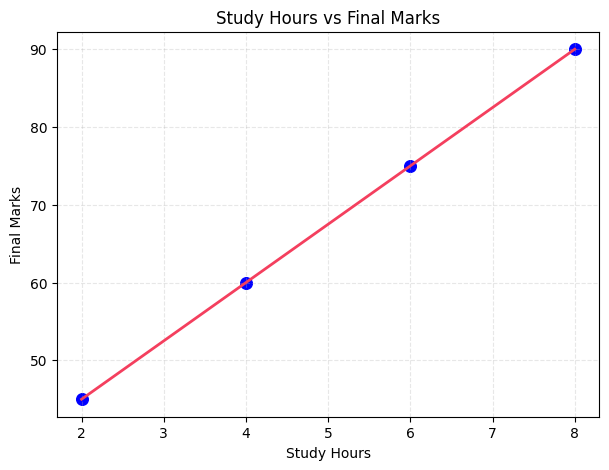

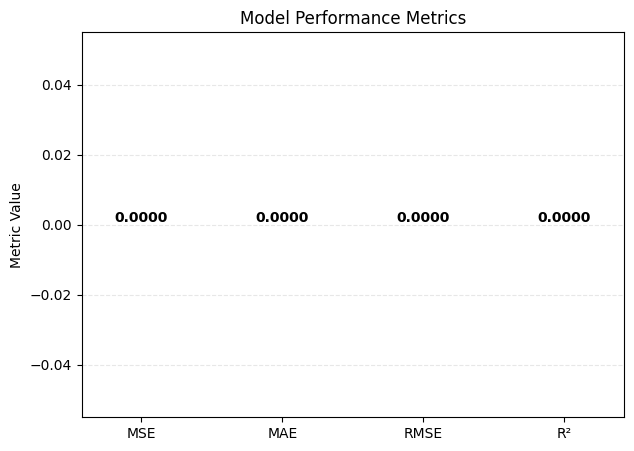


PREDICT FINAL MARKS FOR A NEW STUDENT


KeyboardInterrupt: Interrupted by user

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ==============================
# USER INPUT DATASET
# ==============================

n = int(input("Enter number of student records: "))

study_hours = []
attendance = []
assignment = []
final_marks = []

for i in range(n):
    print(f"\nStudent {i+1}")

    study_hours.append(float(input("Study Hours: ")))
    attendance.append(float(input("Attendance (%): ")))
    assignment.append(float(input("Assignment Score: ")))
    final_marks.append(float(input("Final Marks: ")))

# ==============================
# CREATE DATAFRAME
# ==============================

df = pd.DataFrame({
    "Study Hours": study_hours,
    "Attendance": attendance,
    "Assignment": assignment,
    "Final Marks": final_marks
})

print("\nDataset:")
print(df)

# Save Dataset
df.to_csv("Student_Data.csv", index=False)

# ==============================
# FEATURE SELECTION
# ==============================

X = df[["Study Hours", "Attendance", "Assignment"]]
y = df["Final Marks"]

# ==============================
# TRAIN TEST SPLIT
# ==============================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# ==============================
# MODEL TRAINING
# ==============================

model = LinearRegression()
model.fit(X_train, y_train)

# ==============================
# PREDICTIONS
# ==============================

y_pred = model.predict(X_test)

# ==============================
# REGRESSION EQUATION
# ==============================

print("\nGENERAL REGRESSION EQUATION")
print("Y = b0 + b1X1 + b2X2 + b3X3")

print("\nWhere:")
print("Y  = Final Marks")
print("X1 = Study Hours")
print("X2 = Attendance")
print("X3 = Assignment Score")

print("\nMODEL COEFFICIENTS")

for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef:.4f}")

print(f"Intercept (b0): {model.intercept_:.4f}")

print("\nLEARNED REGRESSION EQUATION")

print(
    f"Final Marks = {model.intercept_:.2f} + "
    f"{model.coef_[0]:.2f}(Study Hours) + "
    f"{model.coef_[1]:.2f}(Attendance) + "
    f"{model.coef_[2]:.2f}(Assignment)"
)

# ==============================
# ERROR METRICS
# ==============================

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

if len(y_test) > 1:
    r2 = r2_score(y_test, y_pred)
else:
    r2 = 0

print("\nMODEL PERFORMANCE")

print(f"MSE  : {mse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

# ==============================
# GRAPH 1
# STUDY HOURS VS FINAL MARKS
# ==============================

plot_df = df.sort_values("Study Hours")

plt.figure(figsize=(7,5))

plt.plot(
    plot_df["Study Hours"],
    plot_df["Final Marks"],
    '-',
    color="#f43f5e",
    linewidth=2
)

plt.scatter(
    plot_df["Study Hours"],
    plot_df["Final Marks"],
    color="blue",
    s=70
)

plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.title("Study Hours vs Final Marks")
plt.grid(True, linestyle="--", alpha=0.3)

plt.show()

# ==============================
# GRAPH 2
# ERROR METRICS BAR CHART
# ==============================

metrics_names = ["MSE", "MAE", "RMSE", "R²"]
metrics_vals = [mse, mae, rmse, r2]

colors = ["#a855f7", "#08d6d4", "#f43f5e", "#10b981"]

plt.figure(figsize=(7,5))

bars = plt.bar(
    metrics_names,
    metrics_vals,
    color=colors,
    width=0.5
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.title("Model Performance Metrics")
plt.ylabel("Metric Value")
plt.grid(True, axis="y", linestyle="--", alpha=0.3)

plt.show()

# ==============================
# USER PREDICTION
# ==============================

print("\nPREDICT FINAL MARKS FOR A NEW STUDENT")

hours = float(input("Study Hours: "))
att = float(input("Attendance (%): "))
assign = float(input("Assignment Score: "))

new_student = pd.DataFrame({
    "Study Hours": [hours],
    "Attendance": [att],
    "Assignment": [assign]
})

prediction = model.predict(new_student)

print(f"\nPredicted Final Marks = {prediction[0]:.2f}")